In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from DTT_func import *
import DTT_func
importlib.reload(DTT_func)
from DTT_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18


## Get Calibration

In [2]:
## Good calib for nanoscope 2

#dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2024-10'
#dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2025-03'

#dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-06'


dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-08'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


## Compute extinction spectra

### To allow for the computation, we need a specific directory managment :

dir_root : the main directory
dir_name : the directory with data to compute a single spectra. 

Into that directory is an excel which name is exactly 'dir_name', containing experimental measurments : DTT, V_off, V.

    DTT : maximum DTT signal measured.
    V_off : dark current voltage of the photodiode (important for low fluence measurments).
    V : photodiode current during the measure (usefull to compensate the dark current).

In the excel, each source is in a different sheet, the sheet is named after the source (with 3 letter : OPO, SHG, CHA).

The Spectra units are :

    Wavelength : in m
    Energy : in eV
    Exctinction cross section : in m2
    

In [ ]:
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 2.3\isolated' 

Spectra_Data['isolated ND1 - polar 0'] = Spectra_computation(dir_root1, 'D1', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '27-Oct-2026_Spectre_theta_0', force_recomputation=False, spectra_title = '', method='fine')
Spectra_Data['isolated ND1 - polar 90'] = Spectra_computation(dir_root1, 'D1', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '27-Oct-2026_Spectre_theta_90', force_recomputation=False, spectra_title = '', method='fine')

OPO
------------------------------
lambda = 540.0
fwhm = 336.5157086457376
------------------------------
------------------------------
lambda = 550.0
fwhm = 339.2759947224159
------------------------------
------------------------------
lambda = 570.0
fwhm = 351.1747137807166
------------------------------
------------------------------
lambda = 590.0000000000001
fwhm = 363.0708267838234
------------------------------
------------------------------
lambda = 610.0000000000001
fwhm = 379.949603269204
------------------------------
------------------------------
lambda = 630.0
fwhm = 399.3837571061887
------------------------------
SHG
OPO
------------------------------
lambda = 540.0
fwhm = 336.5157086457376
------------------------------
------------------------------
lambda = 550.0
fwhm = 339.2759947224159
------------------------------
------------------------------
lambda = 570.0
fwhm = 351.1747137807166
------------------------------
------------------------------


## Plot all Spectra

In [ ]:
Plot_info = {}
Plot_info['fontsize'] = 25

Plot_info['Markers'] = {}
Plot_info['Markers']['SHG'] = 'v'
Plot_info['Markers']['OPO'] = '.'
Plot_info['Markers']['CHA'] = '*'
Plot_info['Markers']['MAI'] = '*'

Plot_info['Couleurs'] = {}
Plot_info['Couleurs']['SHG'] = ['#004c6d', '#9dc6e0']
Plot_info['Couleurs']['OPO'] = ['#488f31', '#b6ccab']
Plot_info['Couleurs']['CHA'] = ['#de425b', '#efb7b8']
Plot_info['Couleurs']['MAI'] = ['#de425b', '#efb7b8']

Show raw spectra data

In [ ]:
os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Experimental\Salle_particules_unique\Nanodisks\Lithographies\ND4-01-col2\Calib 16 septembre 2024')

show_raw_spectra = 0

if show_raw_spectra :

    for key in Spectra_Data :

        data = Spectra_Data[key]
        fig, ax = spectra_simple_plot(Spectra_Data[key], Plot_info)

        os.chdir(Spectra_Data[key]['dir_root'] + r'\\' +  Spectra_Data[key]['dir_name'])
        #plt.savefig(Spectra_Data[key]['fname'] + '.png')

In [ ]:
show_all_raw_spectra = 0

if show_all_raw_spectra :
    fig, ax = all_spectra_plot(Spectra_Data, Plot_info)

    #plt.savefig('Spectra.pdf')
    #plt.savefig('Spectra.png')

## Lorentzian fit

In [ ]:
Res_fit = {}
for key in Spectra_Data :
    data = Spectra_Data[key]
    Res_fit[key] = Lorentz_fit_energy_spectra(data)

75.89889809889553


C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas\Spectra_plotting.py:192: RuntimeWarning: divide by zero encountered in divide
  return 1240/x


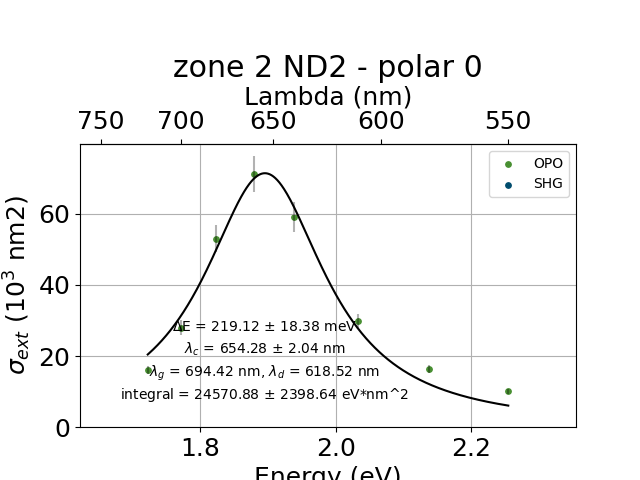

74.32274893936255


C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas\Spectra_plotting.py:192: RuntimeWarning: divide by zero encountered in divide
  return 1240/x


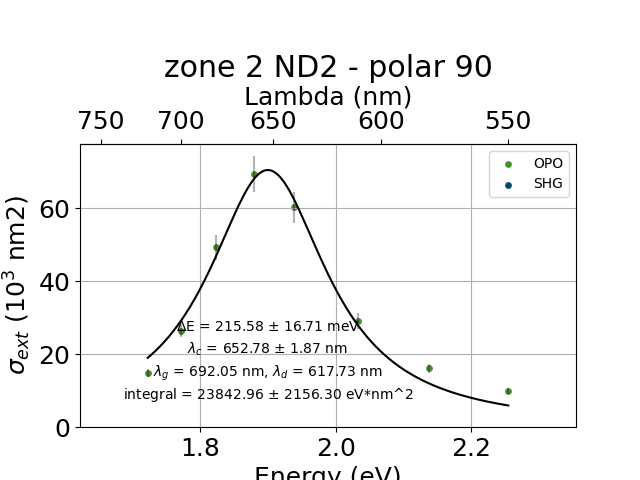

In [ ]:
for key in Spectra_Data :
    data = Spectra_Data[key]
    res_fit = Res_fit[key]
    print(res_fit['Delta_lda'])
    fig, ax = plot_lorentz_single(data, res_fit, Plot_info, key)
    #fig, ax = plot_lorentz_single_nofit(data, res_fit, Plot_info, key)
    plt.tight_layout()
    os.chdir(data['dir_root'] +'\\' +  data['dir_name'])
    plt.savefig(data['title']+ '.png')
    plt.savefig(data['title']+ '.pdf')

### Plot fits together

C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas\Spectra_plotting.py:332: RuntimeWarning: divide by zero encountered in divide
  return 1240/x


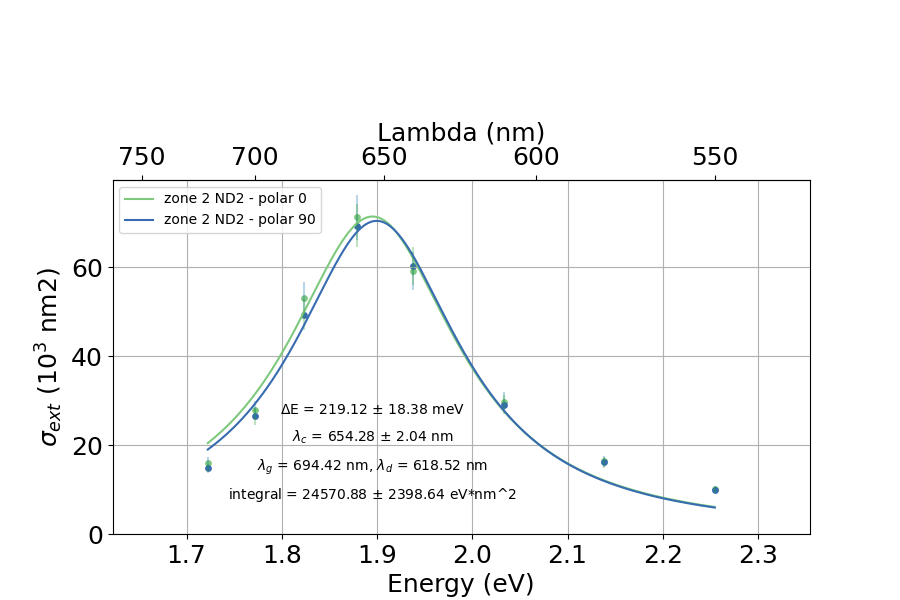

In [ ]:
plusieurs_spectres = 1
if plusieurs_spectres :
    key_list = [ 'isolated ND1 - polar 0', 'isolated ND1 - polar 90']
    #key_list = ['zone3 - NDe Spectre 0°', 'zone3 - NDe Spectre 0° - après PaP']
    #plot_spectra_together(key_list, Spectra_Data, Res_fit, Plot_info)
    plot_spectra_together_with_fit(key_list, Spectra_Data, Res_fit, Plot_info)
    plt.tight_layout()

    data = Spectra_Data[key_list[0]]

    title = '2026-10-16 - deux polars'
    #title = '21 Jan 2025 - Après PaP'
    #plt.ylim(top=5)
    os.chdir(data['dir_root'] +'\\' +  data['dir_name'])
    plt.savefig(title + '.png')
    plt.savefig(title + '.pdf')